# Yapay Zekâya Giriş – Sınıflandırma ve Iris Veri Seti
Ders dokümanındaki tüm Python kodları, PDF'deki bölüm numaralarıyla aynı sırada.

Gerekli kütüphaneler: `pip install scikit-learn pandas matplotlib seaborn`

## 2. Sınıflandırma (Classification)

### 2.8 Sınıflandırmanın eğitim ve tahmin aşamaları – Eğitim ve tahmin aşamaları: küçük bir spam örneği

In [1]:
from sklearn.tree import DecisionTreeClassifier

# Özellikler: [bağlantı sayısı, "bedava/kazandınız" kelime sayısı]
X_egitim = [[0, 0], [1, 0], [2, 1], [8, 3], [6, 4], [9, 2]]
y_egitim = ["normal", "normal", "normal", "spam", "spam", "spam"]

model = DecisionTreeClassifier(random_state=0)
model.fit(X_egitim, y_egitim)              # 1) Eğitim aşaması

yeni_epostalar = [[1, 1], [7, 5]]
tahminler = model.predict(yeni_epostalar)  # 2) Tahmin aşaması
print(tahminler)

['normal' 'spam']


## 3. Model Başarı Metrikleri

### 3.7 Sayısal örnek: tüm metriklerin hesaplanması – Metriklerin scikit-learn ile hesaplanması

In [2]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

y_gercek = ["spam"] * 50 + ["normal"] * 50
y_tahmin = (["spam"] * 40 + ["normal"] * 10 +    # 50 gerçek spam
            ["spam"] * 5 + ["normal"] * 45)      # 50 gerçek normal

print(confusion_matrix(y_gercek, y_tahmin, labels=["spam", "normal"]))
print("Accuracy :", accuracy_score(y_gercek, y_tahmin))
print("Precision:", round(precision_score(y_gercek, y_tahmin,
                                          pos_label="spam"), 3))
print("Recall   :", recall_score(y_gercek, y_tahmin, pos_label="spam"))
print("F1-score :", round(f1_score(y_gercek, y_tahmin,
                                   pos_label="spam"), 3))

[[40 10]
 [ 5 45]]
Accuracy : 0.85
Precision: 0.889
Recall   : 0.8
F1-score : 0.842


### 3.9 Eğitim-test ayrımı (train-test split) – Iris verisini eğitim ve test olarak bölmek

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Eğitim:", X_train.shape, " Test:", X_test.shape)
print("Testteki sınıf sayıları:", np.bincount(y_test))

Eğitim: (120, 4)  Test: (30, 4)
Testteki sınıf sayıları: [10 10 10]


## 5. Python ile Iris Veri Setini Yükleme ve İnceleme

### 5.1 scikit-learn kütüphanesi – Kurulum kontrolü

In [4]:
import sklearn, pandas, matplotlib, seaborn

print("scikit-learn:", sklearn.__version__)
print("pandas      :", pandas.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", seaborn.__version__)

scikit-learn: 1.9.1
pandas      : 3.0.5
matplotlib  : 3.11.2
seaborn     : 0.13.2


### 5.2 Iris veri setini yükleme: load_iris() – Veri setini yükleyip tamamını yazdırmak

In [5]:
from sklearn.datasets import load_iris

iris = load_iris()

print(iris)

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

### Bunch nesnesinin anahtarları

In [6]:
from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))
print(list(iris.keys()))

<class 'sklearn.utils._bunch.Bunch'>
['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']


### 5.3 data, target, feature_names ve target_names – Veri setinin dört temel bileşeni

In [7]:
print(iris.data)
print(iris.target)
print(iris.feature_names)
print(iris.target_names)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

### Boyutlar ve tek bir çiçeğe erişim

In [8]:
print(iris.data.shape)
print(iris.target.shape)
print(iris.data[0])
print(iris.target[0], iris.target[50], iris.target[100])

(150, 4)
(150,)
[5.1 3.5 1.4 0.2]
0 1 2


### Kodları tür adlarına çevirmek

In [9]:
for kod, ad in enumerate(iris.target_names):
    print(kod, "->", ad)

ornekler = [0, 56, 147]
print(iris.target[ornekler])
print(iris.target_names[iris.target[ornekler]])

0 -> setosa
1 -> versicolor
2 -> virginica
[0 1 2]
['setosa' 'versicolor' 'virginica']


### 5.4 pandas ile veri setini inceleme – Iris verisini DataFrame'e dönüştürmek

In [10]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


### df.info()

In [11]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


### df.describe()

In [12]:
print(df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)     species  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


### df.shape

In [13]:
print(df.shape)

(150, 5)


### df.isnull().sum()

In [14]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


### df['species'].value_counts()

In [15]:
print(df["species"].value_counts())

species
0    50
1    50
2    50
Name: count, dtype: int64


### Türlere göre ortalama ölçüler

In [16]:
print(df.groupby("species").mean().round(2))

         sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                           
0                     5.01              3.43               1.46   
1                     5.94              2.77               4.26   
2                     6.59              2.97               5.55   

         petal width (cm)  
species                    
0                    0.25  
1                    1.33  
2                    2.03  


## 6. Iris Veri Setinin Görselleştirilmesi

### 6.1 Hazırlık kodu – Grafikler için ortak hazırlık

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target
df["tur"] = df["species"].map({0: "setosa", 1: "versicolor",
                               2: "virginica"})

renkler = {"setosa": "#2a78d6", "versicolor": "#eb6834",
           "virginica": "#1baf7a"}
sns.set_theme(style="whitegrid")
print(df[["species", "tur"]].drop_duplicates())

     species         tur
0          0      setosa
50         1  versicolor
100        2   virginica


### 6.2 Sütun grafiği (bar chart) – Sütun grafikleri

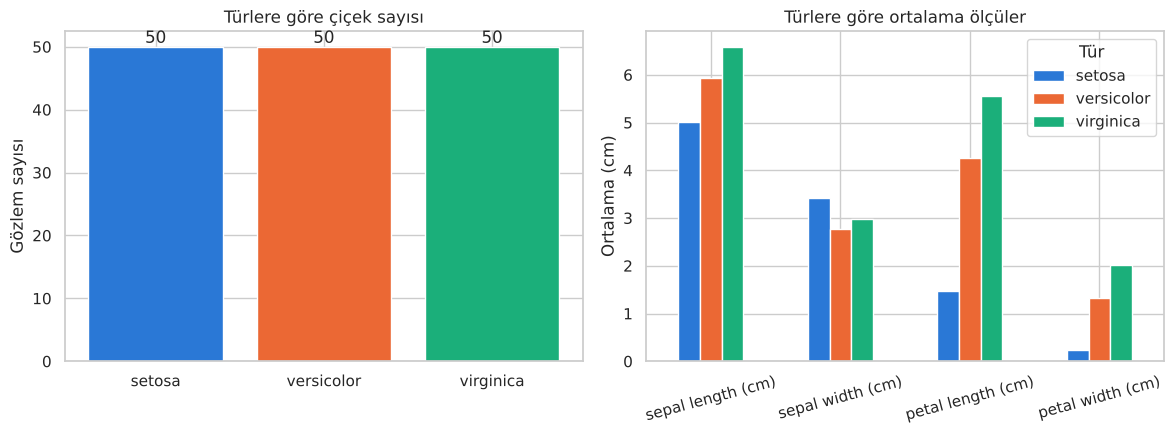

In [18]:
sayilar = df["tur"].value_counts().sort_index()
ortalamalar = df.groupby("tur")[iris.feature_names].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(sayilar.index, sayilar.values,
            color=[renkler[t] for t in sayilar.index])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title("Türlere göre çiçek sayısı")
axes[0].set_ylabel("Gözlem sayısı")

ortalamalar.T.plot(kind="bar", ax=axes[1],
                   color=[renkler[t] for t in ortalamalar.index])
axes[1].set_title("Türlere göre ortalama ölçüler")
axes[1].set_ylabel("Ortalama (cm)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Tür")

plt.tight_layout()
plt.show()

### 6.3 Histogram – Histogramlar

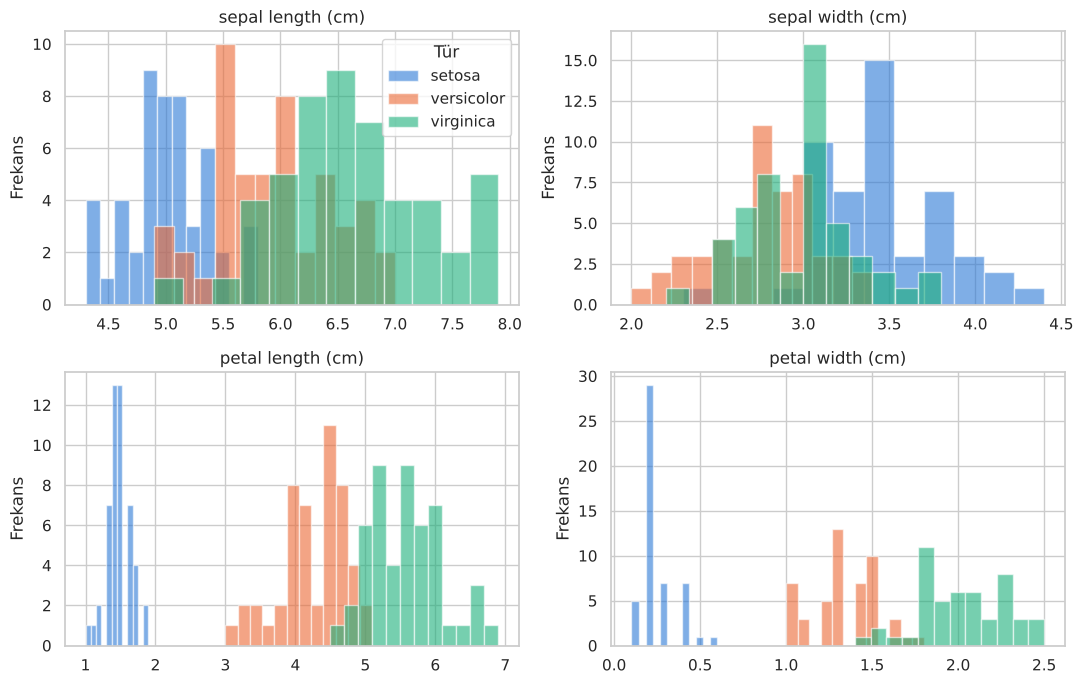

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, ozellik in zip(axes.flat, iris.feature_names):
    for tur, renk in renkler.items():
        degerler = df.loc[df["tur"] == tur, ozellik]
        ax.hist(degerler, bins=12, alpha=0.6, color=renk,
                label=tur, edgecolor="white")
    ax.set_title(ozellik)
    ax.set_ylabel("Frekans")

axes[0, 0].legend(title="Tür")
plt.tight_layout()
plt.show()

### 6.4 Saçılım grafiği (scatter plot) – Saçılım grafikleri

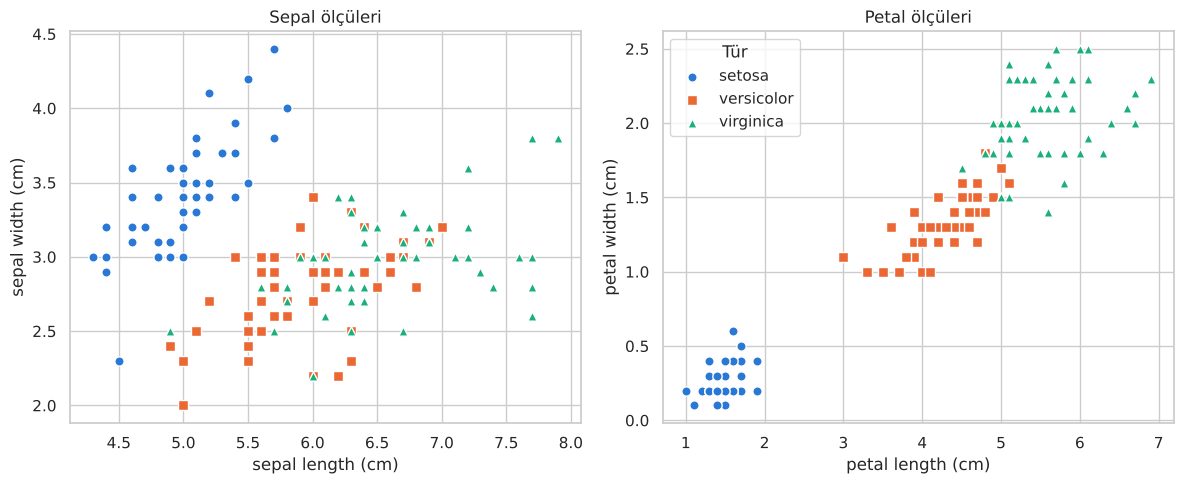

In [20]:
isaretler = {"setosa": "o", "versicolor": "s", "virginica": "^"}
ciftler = [("sepal length (cm)", "sepal width (cm)"),
           ("petal length (cm)", "petal width (cm)")]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (x_ozellik, y_ozellik) in zip(axes, ciftler):
    for tur, renk in renkler.items():
        secim = df[df["tur"] == tur]
        ax.scatter(secim[x_ozellik], secim[y_ozellik], color=renk,
                   marker=isaretler[tur], s=45, edgecolor="white",
                   label=tur)
    ax.set_xlabel(x_ozellik)
    ax.set_ylabel(y_ozellik)

axes[0].set_title("Sepal ölçüleri")
axes[1].set_title("Petal ölçüleri")
axes[1].legend(title="Tür")
plt.tight_layout()
plt.show()

### 6.5 Çiftli grafik (pairplot) – Pairplot

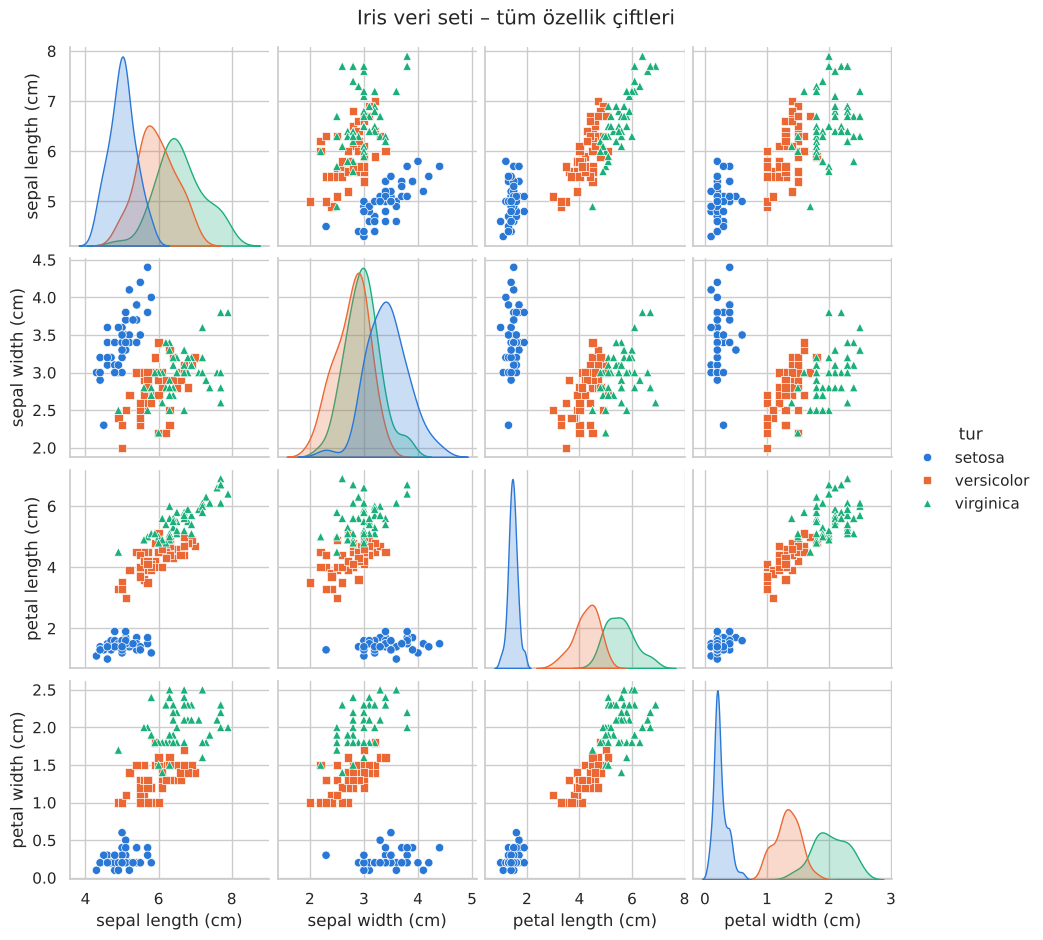

In [21]:
g = sns.pairplot(df.drop(columns="species"), hue="tur",
                 hue_order=list(renkler), palette=renkler,
                 markers=["o", "s", "^"], height=2.3)
g.figure.suptitle("Iris veri seti – tüm özellik çiftleri", y=1.02)
plt.show()

### 6.6 Korelasyon ısı haritası (correlation heatmap) – Korelasyon ısı haritası

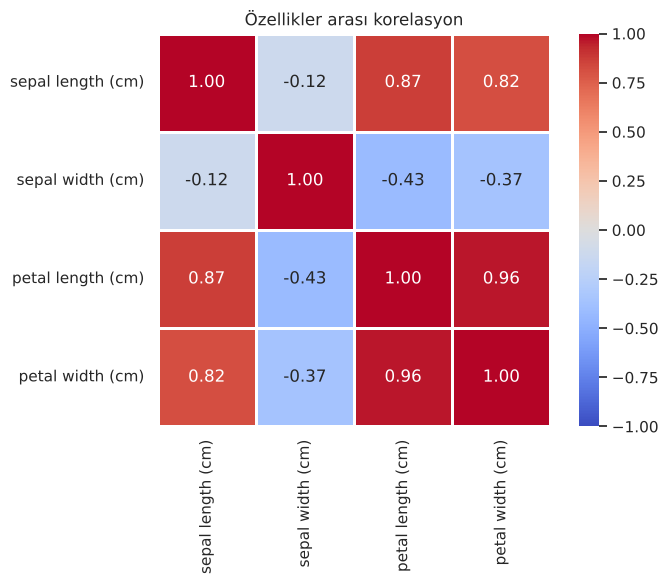

In [22]:
korelasyon = df[iris.feature_names].corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(korelasyon, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=2)
plt.title("Özellikler arası korelasyon")
plt.tight_layout()
plt.show()

## 7. Iris ile İlk Sınıflandırma Modeli

### 7.1 Modelin eğitilmesi ve test edilmesi – Karar ağacı ile Iris sınıflandırması

In [23]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

egitim_basari = accuracy_score(y_train, model.predict(X_train))
print("Eğitim doğruluğu:", egitim_basari)
print("Test doğruluğu  :", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred,
                            target_names=iris.target_names))

Eğitim doğruluğu: 1.0
Test doğruluğu  : 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### 7.2 Çok sınıflı karışıklık matrisi – Karışıklık matrisini çizmek

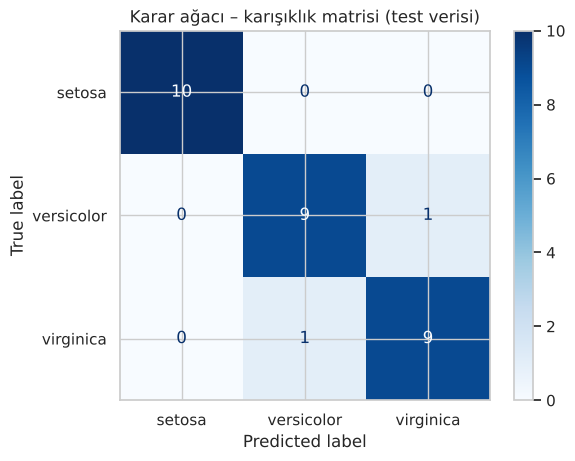

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names, cmap="Blues")
plt.title("Karar ağacı – karışıklık matrisi (test verisi)")
plt.show()

### 7.3 Yeni bir çiçeğin türünü tahmin etmek – Yeni bir çiçek için tahmin

In [25]:
yeni_cicek = [[6.4, 3.1, 5.5, 1.8]]
tahmin = model.predict(yeni_cicek)
print("Tahmin edilen kod:", tahmin)
print("Tahmin edilen tür:", iris.target_names[tahmin][0])

Tahmin edilen kod: [2]
Tahmin edilen tür: virginica
